In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, precision_score, recall_score, roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.calibration import CalibratedClassifierCV
import xgboost as xgb
import shap

Mapping

In [66]:
attribute_names = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_rate", "personal_status_sex",
    "other_debtors", "residence_since", "property", "age", "other_installment_plans",
    "housing", "existing_credits", "job", "num_dependents", "telephone",
    "foreign_worker", "target"
]

code_maps = {
    "checking_status": {
        "A11": "< 0 DM",
        "A12": "0 <= ... < 200 DM",
        "A13": ">= 200 DM / salary assignment",
        "A14": "no checking account"
    },
    "credit_history": {
        "A30": "no credits taken/all paid duly",
        "A31": "all credits at this bank paid duly",
        "A32": "existing credits paid duly till now",
        "A33": "delay in paying off in the past",
        "A34": "critical account/other credits existing"
    },
    "purpose": {
        "A40": "car (new)",
        "A41": "car (used)",
        "A42": "furniture/equipment",
        "A43": "radio/television",
        "A44": "domestic appliances",
        "A45": "repairs",
        "A46": "education",
        "A47": "vacation",
        "A48": "retraining",
        "A49": "business",
        "A410": "other"
    },
    "savings_status": {
        "A61": "< 100 DM",
        "A62": "100 <= ... < 500 DM",
        "A63": "500 <= ... < 1000 DM",
        "A64": ">= 1000 DM",
        "A65": "unknown/no savings account"
    },
    "employment": {
        "A71": "unemployed",
        "A72": "< 1 year",
        "A73": "1 <= ... < 4 years",
        "A74": "4 <= ... < 7 years",
        "A75": ">= 7 years"
    },
    "personal_status_sex": {
        "A91": "male: divorced/separated",
        "A92": "female: divorced/separated/married",
        "A93": "male: single",
        "A94": "male: married/widowed",
        "A95": "female: single"
    },
    "other_debtors": {
        "A101": "none",
        "A102": "co-applicant",
        "A103": "guarantor"
    },
    "property": {
        "A121": "real estate",
        "A122": "building society savings/life insurance",
        "A123": "car or other property",
        "A124": "unknown/no property"
    },
    "other_installment_plans": {
        "A141": "bank",
        "A142": "stores",
        "A143": "none"
    },
    "housing": {
        "A151": "rent",
        "A152": "own",
        "A153": "for free"
    },
    "job": {
        "A171": "unemployed/unskilled non-resident",
        "A172": "unskilled resident",
        "A173": "skilled employee/official",
        "A174": "management/self-employed/highly qualified"
    },
    "telephone": {
        "A191": "none",
        "A192": "yes, registered"
    },
    "foreign_worker": {
        "A201": "yes",
        "A202": "no"
    },
    "target": {
        1: "good",
        2: "bad"
    }
}

df = pd.read_csv(
    "german.data",
    sep=r"\s+",
    header=None,
    names=attribute_names
)

for col, mapping in code_maps.items():
    df[col] = df[col].map(mapping)

print(df.shape)
print(df.head())
print(df.isna().sum())  # should be all zeros if mapping was applied correctly

(1000, 21)
       checking_status  duration                           credit_history  \
0               < 0 DM         6  critical account/other credits existing   
1    0 <= ... < 200 DM        48      existing credits paid duly till now   
2  no checking account        12  critical account/other credits existing   
3               < 0 DM        42      existing credits paid duly till now   
4               < 0 DM        24          delay in paying off in the past   

               purpose  credit_amount              savings_status  \
0     radio/television           1169  unknown/no savings account   
1     radio/television           5951                    < 100 DM   
2            education           2096                    < 100 DM   
3  furniture/equipment           7882                    < 100 DM   
4            car (new)           4870                    < 100 DM   

           employment  installment_rate                 personal_status_sex  \
0          >= 7 years           

Give 0 to good and 1 to bad

In [67]:
df["target"] = (df["target"] == "bad").astype(int)

print(df["target"].value_counts())

target
0    700
1    300
Name: count, dtype: int64


A little data analysis to get to understand what we are dealing with

=== Class Balance ===
target
0    700
1    300
Name: count, dtype: int64

Proportions:
target
0    70.0%
1    30.0%
Name: proportion, dtype: str

=== Numeric Summary Statistics by Target ===
target                          0            1
age           mean      36.224286    33.963333
              median    34.000000    31.000000
              std       11.381145    11.222379
duration      mean      19.207143    24.860000
              median    18.000000    24.000000
              std       11.079564    13.282639
credit_amount mean    2985.457143  3938.126667
              median  2244.000000  2574.500000
              std     2401.472278  3535.818955


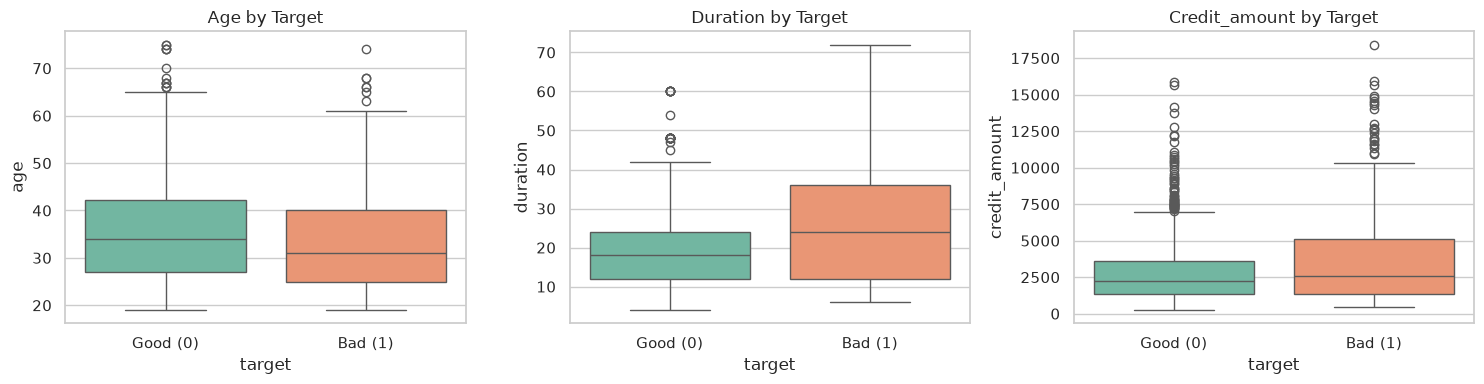


=== Bad Rate by Key Categoricals ===

--- checking_status ---
                               total_count  bad_count  bad_rate_%
checking_status                                                  
< 0 DM                                 274        135       49.27
0 <= ... < 200 DM                      269        105       39.03
>= 200 DM / salary assignment           63         14       22.22
no checking account                    394         46       11.68

--- credit_history ---
                                         total_count  bad_count  bad_rate_%
credit_history                                                             
no credits taken/all paid duly                    40         25       62.50
all credits at this bank paid duly                49         28       57.14
existing credits paid duly till now              530        169       31.89
delay in paying off in the past                   88         28       31.82
critical account/other credits existing          293         

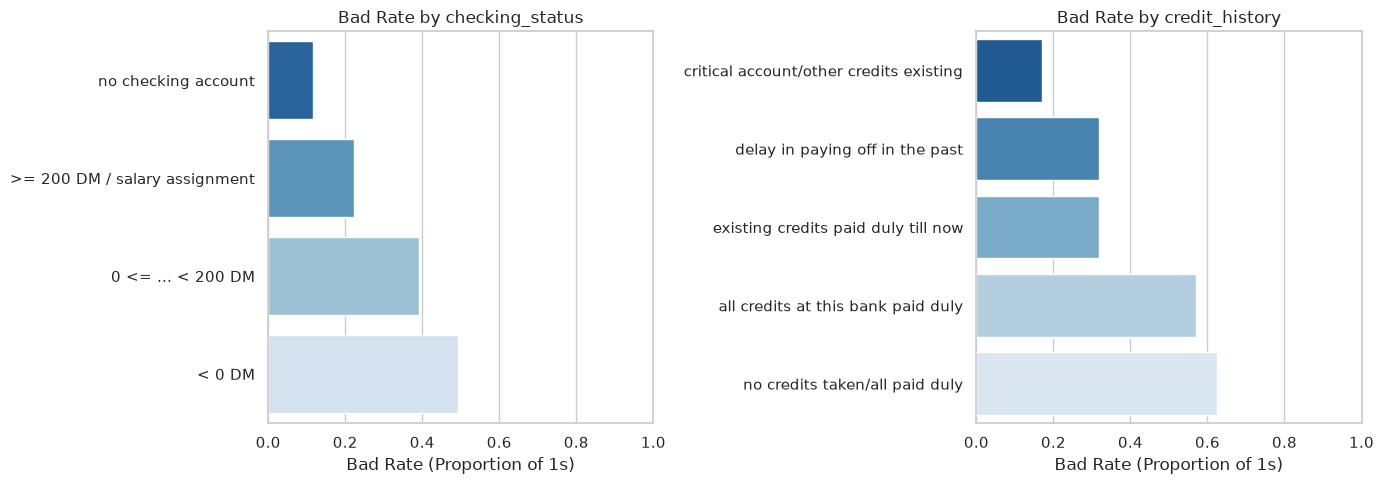

In [68]:
sns.set_theme(style="whitegrid")

print("=== Class Balance ===")
print(df["target"].value_counts())
print("\nProportions:")
print(df["target"].value_counts(normalize=True).map("{:.1%}".format))


num_cols = ["age", "duration", "credit_amount"]

print("\n=== Numeric Summary Statistics by Target ===")
print(df.groupby("target")[num_cols].agg(["mean", "median", "std"]).T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, col in enumerate(num_cols):
    sns.boxplot(
        data=df, 
        x="target", 
        y=col, 
        hue="target", 
        ax=axes[idx], 
        palette="Set2", 
        legend=False
    )
    axes[idx].set_title(f"{col.capitalize()} by Target")
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(["Good (0)", "Bad (1)"])

plt.tight_layout()
plt.show()


key_cats = ["checking_status", "credit_history"]

print("\n=== Bad Rate by Key Categoricals ===")
for col in key_cats:
    summary = df.groupby(col)["target"].agg(
        total_count="count",
        bad_count="sum",
        bad_rate="mean"
    ).sort_values(by="bad_rate", ascending=False)
    
    summary["bad_rate_%"] = (summary["bad_rate"] * 100).round(2)
    print(f"\n--- {col} ---")
    print(summary[["total_count", "bad_count", "bad_rate_%"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, col in enumerate(key_cats):
    bad_rates = df.groupby(col)["target"].mean().sort_values().reset_index()
    sns.barplot(
        data=bad_rates, 
        x="target", 
        y=col, 
        hue=col, 
        ax=axes[idx], 
        palette="Blues_r", 
        legend=False
    )
    axes[idx].set_xlabel("Bad Rate (Proportion of 1s)")
    axes[idx].set_ylabel("")
    axes[idx].set_title(f"Bad Rate by {col}")
    axes[idx].set_xlim(0, 1)

plt.tight_layout()
plt.show()

Train/test split by 80/20. We have 70% of good and 30% bad in each of training and testing sets

In [69]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}\n")

print("Train target proportions:")
print(y_train.value_counts(normalize=True).map("{:.1%}".format))

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True).map("{:.1%}".format))

X_train shape: (800, 20), X_test shape: (200, 20)

Train target proportions:
target
0    70.0%
1    30.0%
Name: proportion, dtype: str

Test target proportions:
target
0    70.0%
1    30.0%
Name: proportion, dtype: str


Encoding.

Give One-Hot Encoding and Ordinal Encoding to the corresponding features

In [70]:
savings_map = {
    "unknown/no savings account": 0,
    "< 100 DM": 1,
    "100 <= ... < 500 DM": 2,
    "500 <= ... < 1000 DM": 3,
    ">= 1000 DM": 4,
}

employment_map = {
    "unemployed": 0,
    "< 1 year": 1,
    "1 <= ... < 4 years": 2,
    "4 <= ... < 7 years": 3,
    ">= 7 years": 4,
}

checking_map = {
    "no checking account": 0,
    "< 0 DM": 1,
    "0 <= ... < 200 DM": 2,
    ">= 200 DM / salary assignment": 3,
}

for dataset in [X_train, X_test]:
    dataset["savings_status"] = dataset["savings_status"].map(savings_map)
    dataset["employment"] = dataset["employment"].map(employment_map)
    dataset["checking_status"] = dataset["checking_status"].map(checking_map)



nominal_cols = [
    "credit_history",
    "purpose",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker",
]

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train[nominal_cols])

encoded_train = pd.DataFrame(
    ohe.transform(X_train[nominal_cols]),
    columns=ohe.get_feature_names_out(nominal_cols),
    index=X_train.index,
)

encoded_test = pd.DataFrame(
    ohe.transform(X_test[nominal_cols]),
    columns=ohe.get_feature_names_out(nominal_cols),
    index=X_test.index,
)

X_train_encoded = pd.concat(
    [X_train.drop(columns=nominal_cols), encoded_train], axis=1
)
X_test_encoded = pd.concat(
    [X_test.drop(columns=nominal_cols), encoded_test], axis=1
)

print(f"X_train_encoded shape: {X_train_encoded.shape}")
print(f"X_test_encoded shape: {X_test_encoded.shape}")

X_train_encoded shape: (800, 40)
X_test_encoded shape: (200, 40)


BONUS: Logistic Regression using Standard Scaler.

In [71]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_encoded),
    columns=X_train_encoded.columns,
    index=X_train_encoded.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_encoded),
    columns=X_test_encoded.columns,
    index=X_test_encoded.index,
)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_proba_train = lr_model.predict_proba(X_train_scaled)[:, 1]
y_proba_test = lr_model.predict_proba(X_test_scaled)[:, 1]

coef_df = pd.DataFrame(
    {
        "Feature": X_train_scaled.columns,
        "Coefficient": lr_model.coef_[0],
        "Abs_Magnitude": np.abs(lr_model.coef_[0]),
    }
).sort_values(by="Abs_Magnitude", ascending=False)

print("=== Top 15 Features by Magnitude (Direction & Effect) ===")
print(coef_df.head(15).to_string(index=False))

=== Top 15 Features by Magnitude (Direction & Effect) ===
                                               Feature  Coefficient  Abs_Magnitude
credit_history_critical account/other credits existing    -0.578878       0.578878
                                       checking_status     0.390741       0.390741
                                      installment_rate     0.384026       0.384026
                                          housing_rent     0.363792       0.363792
                                     purpose_car (new)     0.342243       0.342243
                                              duration     0.315930       0.315930
                          property_unknown/no property     0.311700       0.311700
                          other_installment_plans_none    -0.299293       0.299293
                                         credit_amount     0.269082       0.269082
                                     purpose_education     0.258696       0.258696
                      persona

We balance everything.

In [72]:
lr_unweighted = LogisticRegression(max_iter=1000, random_state=42)
lr_unweighted.fit(X_train_scaled, y_train)

lr_weighted = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr_weighted.fit(X_train_scaled, y_train)


y_pred_unweighted = lr_unweighted.predict(X_test_scaled)
y_pred_weighted = lr_weighted.predict(X_test_scaled)

y_proba_unweighted = lr_unweighted.predict_proba(X_test_scaled)[:, 1]
y_proba_weighted = lr_weighted.predict_proba(X_test_scaled)[:, 1]


comparison_df = pd.DataFrame({
    "Metric": ["Recall (Bad = 1)", "Precision (Bad = 1)", "ROC-AUC"],
    "Unweighted": [
        recall_score(y_test, y_pred_unweighted),
        precision_score(y_test, y_pred_unweighted),
        roc_auc_score(y_test, y_proba_unweighted)
    ],
    "Weighted (class_weight='balanced')": [
        recall_score(y_test, y_pred_weighted),
        precision_score(y_test, y_pred_weighted),
        roc_auc_score(y_test, y_proba_weighted)
    ]
})

print("=== Imbalance Handling Impact (Unweighted vs. Weighted) ===")
print(comparison_df.to_string(index=False))

print("\n" + "="*50)
print("Classification Report: Unweighted")
print("="*50)
print(classification_report(y_test, y_pred_unweighted, target_names=["Good (0)", "Bad (1)"]))

print("="*50)
print("Classification Report: Weighted (class_weight='balanced')")
print("="*50)
print(classification_report(y_test, y_pred_weighted, target_names=["Good (0)", "Bad (1)"]))

=== Imbalance Handling Impact (Unweighted vs. Weighted) ===
             Metric  Unweighted  Weighted (class_weight='balanced')
   Recall (Bad = 1)    0.416667                            0.750000
Precision (Bad = 1)    0.609756                            0.478723
            ROC-AUC    0.760595                            0.760238

Classification Report: Unweighted
              precision    recall  f1-score   support

    Good (0)       0.78      0.89      0.83       140
     Bad (1)       0.61      0.42      0.50        60

    accuracy                           0.74       200
   macro avg       0.69      0.65      0.66       200
weighted avg       0.73      0.74      0.73       200

Classification Report: Weighted (class_weight='balanced')
              precision    recall  f1-score   support

    Good (0)       0.86      0.65      0.74       140
     Bad (1)       0.48      0.75      0.58        60

    accuracy                           0.68       200
   macro avg       0.67      0

XGBoost

In [73]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_base = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
)

calibrated_xgb = CalibratedClassifierCV(
    estimator=xgb_base, method="sigmoid", cv=5
)
calibrated_xgb.fit(X_train_encoded, y_train)

xgb_base.fit(X_train_encoded, y_train)

y_proba_xgb_raw = xgb_base.predict_proba(X_test_encoded)[:, 1]
y_proba_xgb_calibrated = calibrated_xgb.predict_proba(X_test_encoded)[:, 1]

auc = roc_auc_score(y_test, y_proba_xgb_calibrated)
brier_raw = brier_score_loss(y_test, y_proba_xgb_raw)
brier_calibrated = brier_score_loss(y_test, y_proba_xgb_calibrated)

print(f"XGBoost Test ROC-AUC: {auc:.4f}")
print(f"Brier Score - Raw (lower is better): {brier_raw:.4f}")
print(f"Brier Score - Calibrated:           {brier_calibrated:.4f}\n")

risk_scores = pd.DataFrame(
    {
        "Actual_Status": y_test.map({0: "Good", 1: "Bad"}),
        "Raw_XGB_Prob": y_proba_xgb_raw,
        "Calibrated_Default_Probability": y_proba_xgb_calibrated,
    },
    index=X_test.index,
)

print("=== Risk Scoring Model Output (Sample Applicants) ===")
print(risk_scores.head(10).round(4).to_string())

XGBoost Test ROC-AUC: 0.8082
Brier Score - Raw (lower is better): 0.1863
Brier Score - Calibrated:           0.1586

=== Risk Scoring Model Output (Sample Applicants) ===
    Actual_Status  Raw_XGB_Prob  Calibrated_Default_Probability
30           Good        0.4447                          0.2793
128          Good        0.2712                          0.1643
289           Bad        0.8205                          0.6398
216          Good        0.6485                          0.4325
966           Bad        0.4426                          0.3188
346          Good        0.5416                          0.3171
537          Good        0.4225                          0.2668
47           Good        0.3917                          0.2573
112          Good        0.6628                          0.4269
875          Good        0.2478                          0.1562


Threshold selection phase. Plot the cost graph to see which threshold gives how much cost.

=== Threshold Optimization Summary ===
Default Threshold (0.50): Cost = 179 (FN: 33, FP: 14)
Optimal Threshold (0.20): Cost = 99 (FN: 6, FP: 69)
Cost Savings: 80 units (44.7% reduction)


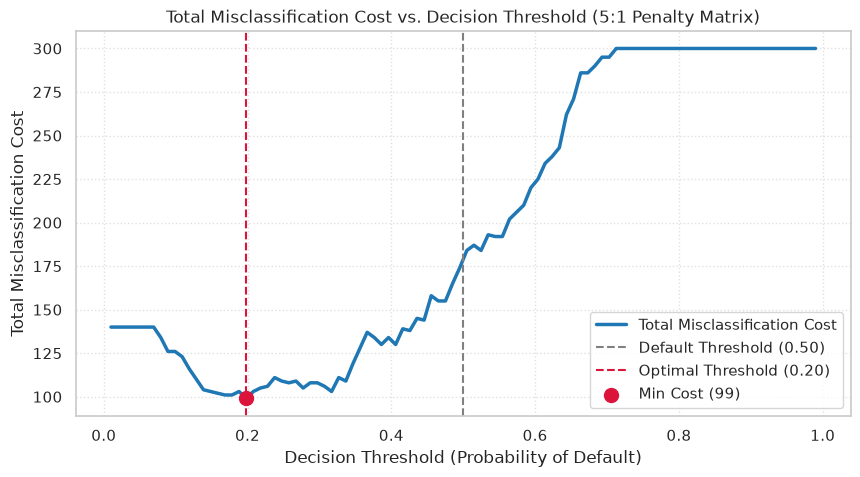

In [74]:
cost_fn = 5
cost_fp = 1

thresholds = np.linspace(0.01, 0.99, 100)
results = []

for t in thresholds:
    y_pred = (y_proba_xgb_calibrated >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    results.append({
        "threshold": t,
        "cost": total_cost,
        "fp": fp,
        "fn": fn
    })

cost_df = pd.DataFrame(results)

opt_idx = cost_df["cost"].idxmin()
opt_threshold = cost_df.loc[opt_idx, "threshold"]
min_cost = cost_df.loc[opt_idx, "cost"]

default_pred = (y_proba_xgb_calibrated >= 0.5).astype(int)
tn_def, fp_def, fn_def, tp_def = confusion_matrix(y_test, default_pred).ravel()
default_cost = (fn_def * cost_fn) + (fp_def * cost_fp)

print("=== Threshold Optimization Summary ===")
print(f"Default Threshold (0.50): Cost = {default_cost} (FN: {fn_def}, FP: {fp_def})")
print(f"Optimal Threshold ({opt_threshold:.2f}): Cost = {int(min_cost)} (FN: {cost_df.loc[opt_idx, 'fn']}, FP: {cost_df.loc[opt_idx, 'fp']})")
print(f"Cost Savings: {default_cost - int(min_cost)} units ({((default_cost - min_cost) / default_cost):.1%} reduction)")

plt.figure(figsize=(10, 5))
plt.plot(cost_df["threshold"], cost_df["cost"], color="#1f77b4", lw=2.5, label="Total Misclassification Cost")

plt.axvline(x=0.50, color="gray", linestyle="--", label="Default Threshold (0.50)")
plt.axvline(x=opt_threshold, color="crimson", linestyle="--", label=f"Optimal Threshold ({opt_threshold:.2f})")
plt.scatter([opt_threshold], [min_cost], color="crimson", zorder=5, s=100, label=f"Min Cost ({int(min_cost)})")

plt.title("Total Misclassification Cost vs. Decision Threshold (5:1 Penalty Matrix)")
plt.xlabel("Decision Threshold (Probability of Default)")
plt.ylabel("Total Misclassification Cost")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

So looking at graph, We see that the best threshold is 0.20. However, that would reject a lot of good customers, therefore, I just somewhere near cost which is higher than 0.20 but still acceptable. I chose 0.35

In [75]:
def evaluate_threshold(y_true, y_prob, threshold, label=""):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    cost_fn = 5  
    cost_fp = 1 
    total_cost = (fn * cost_fn) + (fp * cost_fp)

    return {
        "Threshold": f"{threshold:.2f} ({label})",
        "Approved Good (TN)": tn,
        "False Declines (FP)": fp,
        "Missed Defaults (FN)": fn,
        "Declined Bad (TP)": tp,
        "FP Cost": fp * cost_fp,
        "FN Cost": fn * cost_fn,
        "Total Cost": total_cost,
    }


comparison_data = [
    evaluate_threshold(
        y_test, y_proba_xgb_calibrated, 0.50, "Naive Standard"
    ),
    evaluate_threshold(
        y_test, y_proba_xgb_calibrated, 0.35, "Pre-rise Tradeoff"
    ),
    evaluate_threshold(
        y_test, y_proba_xgb_calibrated, 0.20, "Optimal Minimum"
    ),
]

summary_df = pd.DataFrame(comparison_data)
print("=== Decision Layer Threshold Performance Comparison ===")
print(summary_df.to_string(index=False))



SELECTED_THRESHOLD = 0.35

decisions_df = pd.DataFrame(
    {
        "Calibrated_PD": y_proba_xgb_calibrated,
        "Decision": np.where(
            y_proba_xgb_calibrated >= SELECTED_THRESHOLD, "DECLINE", "APPROVE"
        ),
        "Actual_Status": y_test.map({0: "Good", 1: "Bad"}),
    },
    index=X_test.index,
)

def get_applicant_cost(row):
    if row["Decision"] == "APPROVE" and row["Actual_Status"] == "Bad":
        return 5
    if row["Decision"] == "DECLINE" and row["Actual_Status"] == "Good":
        return 1  
    return 0  

decisions_df["Cost_Incurred"] = decisions_df.apply(get_applicant_cost, axis=1)

print(
    f"\n=== Sample Approve/Decline Output (Threshold = {SELECTED_THRESHOLD}) ==="
)
print(decisions_df.head(10).round(4).to_string())

=== Decision Layer Threshold Performance Comparison ===
               Threshold  Approved Good (TN)  False Declines (FP)  Missed Defaults (FN)  Declined Bad (TP)  FP Cost  FN Cost  Total Cost
   0.50 (Naive Standard)                 126                   14                    33                 27       14      165         179
0.35 (Pre-rise Tradeoff)                 101                   39                    16                 44       39       80         119
  0.20 (Optimal Minimum)                  72                   68                     6                 54       68       30          98

=== Sample Approve/Decline Output (Threshold = 0.2) ===
     Calibrated_PD Decision Actual_Status  Cost_Incurred
30          0.2793  DECLINE          Good              1
128         0.1643  APPROVE          Good              0
289         0.6398  DECLINE           Bad              0
216         0.4325  DECLINE          Good              1
966         0.3188  DECLINE           Bad             

SHAP

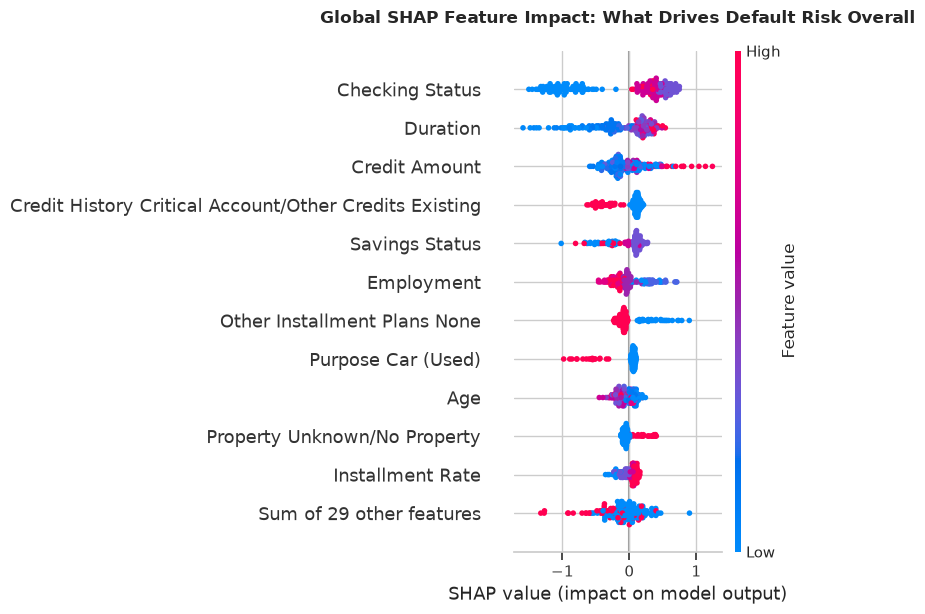

=== Applicant Explanation Targets ===
Declined Applicant Index: 2 | Calibrated Default Prob: 64.0%
Approved Applicant Index: 0 | Calibrated Default Prob: 27.9%



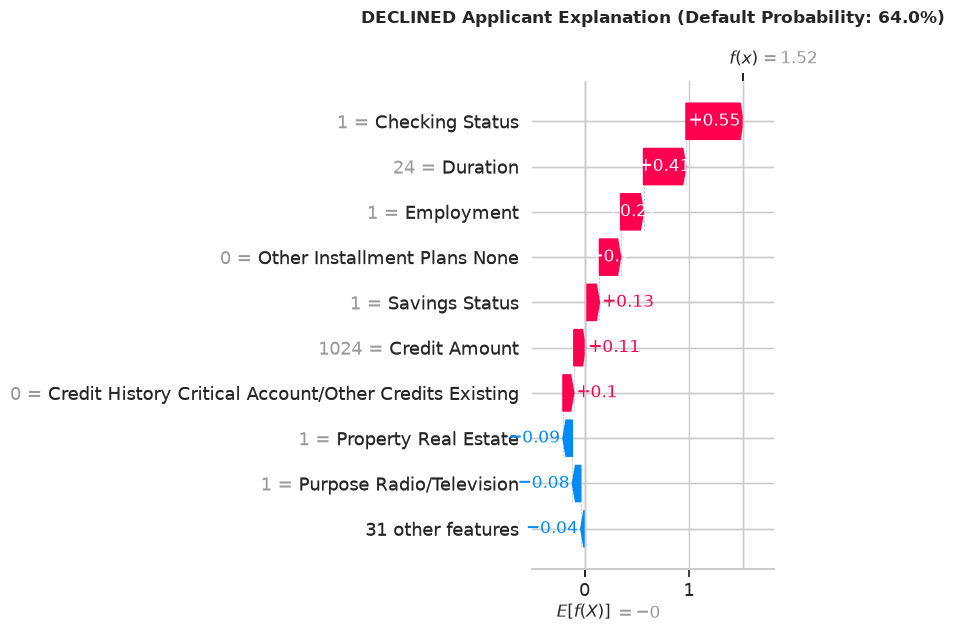

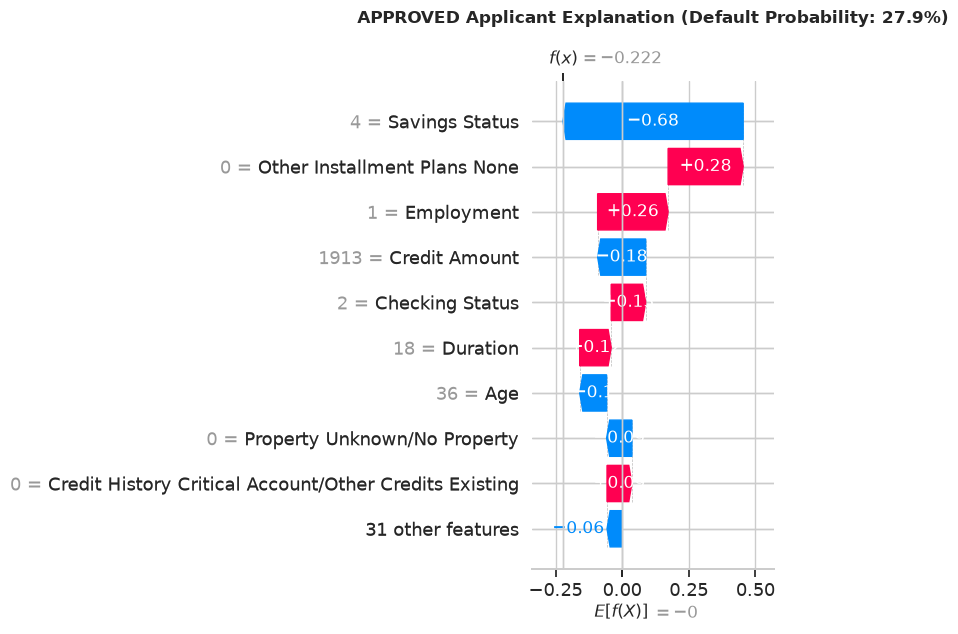

In [76]:
X_test_display = X_test_encoded.copy()
X_test_display.columns = [
    col.replace("_", " ").replace("  ", " ").title()
    for col in X_test_encoded.columns
]

explainer = shap.TreeExplainer(xgb_base)
shap_explanation = explainer(X_test_display)


plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_explanation, max_display=12, show=False)
plt.title(
    "Global SHAP Feature Impact: What Drives Default Risk Overall",
    pad=20,
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


THRESHOLD = 0.35

declined_mask = y_proba_xgb_calibrated >= THRESHOLD
approved_mask = y_proba_xgb_calibrated < THRESHOLD

declined_idx = np.where(declined_mask)[0][0]  
approved_idx = np.where(approved_mask)[0][0]  

print("=== Applicant Explanation Targets ===")
print(
    f"Declined Applicant Index: {declined_idx} | Calibrated Default Prob: {y_proba_xgb_calibrated[declined_idx]:.1%}"
)
print(
    f"Approved Applicant Index: {approved_idx} | Calibrated Default Prob: {y_proba_xgb_calibrated[approved_idx]:.1%}\n"
)



plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_explanation[declined_idx], max_display=10, show=False)
plt.title(
    f"DECLINED Applicant Explanation (Default Probability: {y_proba_xgb_calibrated[declined_idx]:.1%})",
    pad=20,
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_explanation[approved_idx], max_display=10, show=False)
plt.title(
    f"APPROVED Applicant Explanation (Default Probability: {y_proba_xgb_calibrated[approved_idx]:.1%})",
    pad=20,
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()